In [15]:
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

features = ["ax", "ay", "az", "gx", "gy", "gz"]

#Training data
tf = pd.read_csv("ntrain_set.csv", index_col=0) # Get training set
t_features = tf[features]
t_activity = tf["label"]

#Validation data
vf = pd.read_csv("nval_set.csv", index_col=0) # Get training set
v_features = vf[features]
v_activity = vf["label"]


In [16]:
# -----------------------------------------------------------
# Preprocessing of the data so it can be worked on by model
# -----------------------------------------------------------
# Convert the features into numeric values
t_features = t_features[features].apply(pd.to_numeric, errors="coerce")
v_features = v_features[features].apply(pd.to_numeric, errors="coerce")

#print(t_features.isna().sum())
#print(v_features.isna().sum())

# Map the four classes to integer
#class_names = ["jumping", "running", "skipping", "walking"]
label_map = {
    "jumping": 0,
    "running": 1,
    "skipping": 2,
    "walking": 3
}

t_activity = t_activity.map(label_map)
v_activity = v_activity.map(label_map)

#print(t_activity.dtype)
#print(t_activity.unique())

In [17]:
# Create the model
model = keras.Sequential([
    keras.layers.Input(shape=(6,)), # Receives 6 inputs
    keras.layers.Dense(10, activation="relu"),
    keras.layers.Dense(10, activation="relu"),
    keras.layers.Dense(4, activation="softmax") # 4 output neurons for the 4 classes
])

model.compile( # Compile model first so it knows how it should learn before training
    optimizer="adam", # how weights are updated
    loss="sparse_categorical_crossentropy", # what model tries to minimize
    metrics=["accuracy"] # How many predictions are correct
)

history = model.fit( #Start the training process
    t_features,
    t_activity,
    validation_data=(v_features, v_activity),
    epochs=10,
)

print(history.history.keys())

Epoch 1/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.4445 - loss: 1.2274 - val_accuracy: 0.6542 - val_loss: 0.8070
Epoch 2/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.6696 - loss: 0.7528 - val_accuracy: 0.7174 - val_loss: 0.6562
Epoch 3/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.7154 - loss: 0.6535 - val_accuracy: 0.7485 - val_loss: 0.6006
Epoch 4/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7374 - loss: 0.6186 - val_accuracy: 0.7599 - val_loss: 0.5793
Epoch 5/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7479 - loss: 0.6012 - val_accuracy: 0.7723 - val_loss: 0.5598
Epoch 6/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7532 - loss: 0.5907 - val_accuracy: 0.7728 - val_loss: 0.5543
Epoch 7/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7590 - loss: 0.5795 - val_accuracy: 0.7779 - val_loss: 0.5433
Epoch 8/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7629 - loss: 0.57

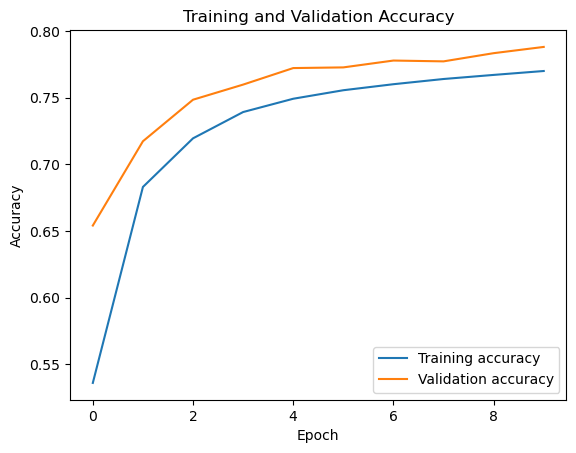

In [18]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

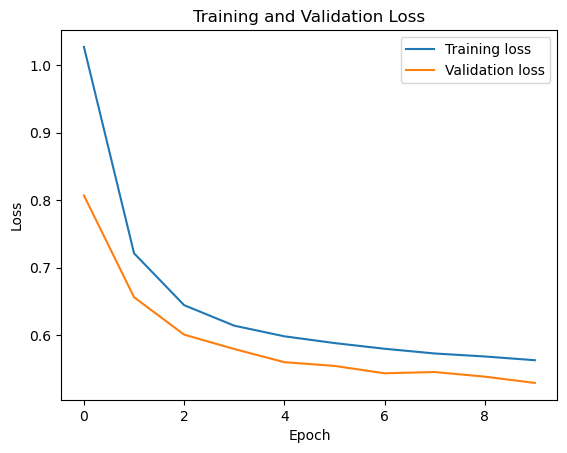

In [19]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [20]:
# -----------------------------------
# Create the Larger Model
# -----------------------------------

model = keras.Sequential([
    keras.layers.Input(shape=(6,)), # Receives 6 inputs
    keras.layers.Dense(50, activation="relu"), # Relu transforms and extract patterns from the sensor data
    keras.layers.Dense(50, activation="relu"),
    keras.layers.Dense(4, activation="softmax") # 4 output neurons for the 4 classes, softmax to choose that with highest propability
])

model.compile( # Compile model first so it knows how it should learn before training
    optimizer="adam", # how weights are updated
    loss="sparse_categorical_crossentropy", # what model tries to minimize
    metrics=["accuracy"] # How many predictions are correct
)

history = model.fit( #Start the training process
    t_features,
    t_activity, 
    validation_data=(v_features, v_activity),
    epochs=10
)

print(history.history.keys())

Epoch 1/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.6672 - loss: 0.8442 - val_accuracy: 0.7996 - val_loss: 0.5270
Epoch 2/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8041 - loss: 0.4989 - val_accuracy: 0.8324 - val_loss: 0.4380
Epoch 3/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8255 - loss: 0.4450 - val_accuracy: 0.8478 - val_loss: 0.4014
Epoch 4/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8323 - loss: 0.4240 - val_accuracy: 0.8505 - val_loss: 0.3888
Epoch 5/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8405 - loss: 0.4090 - val_accuracy: 0.8504 - val_loss: 0.3880
Epoch 6/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8467 - loss: 0.3947 - val_accuracy: 0.8534 - val_loss: 0.3805
Epoch 7/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8488 - loss: 0.3902 - val_accuracy: 0.8591 - val_loss: 0.3616
Epoch 8/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8537 - loss: 0.378

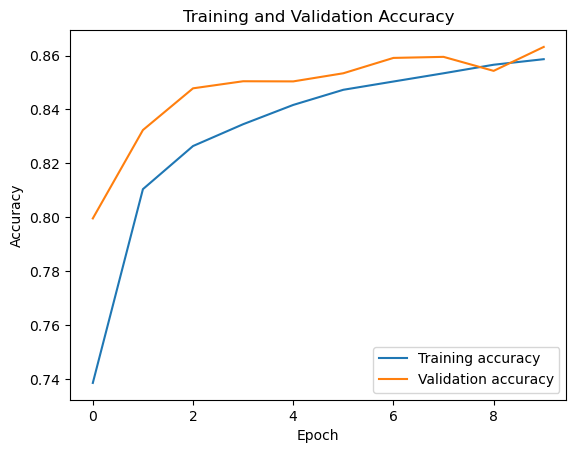

In [21]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

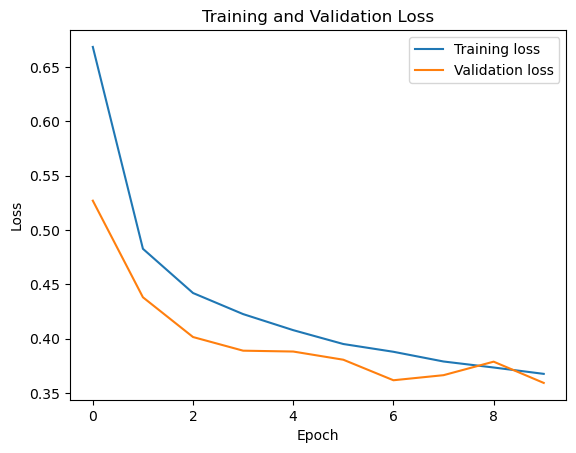

In [22]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [24]:
# -----------------------------------
# SCALED FEEDFORWARD NEURAL NETWORK
# -----------------------------------
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler on training features and transform them
t_features_scaled = scaler.fit_transform(t_features)

# Use the same scaler on validation features
v_features_scaled = scaler.transform(v_features)


model = keras.Sequential([
    keras.layers.Input(shape=(6,)), # Receives 6 inputs
    keras.layers.Dense(50, activation="relu"), # Relu transforms and extract patterns from the sensor data
    keras.layers.Dense(50, activation="relu"),
    keras.layers.Dense(4, activation="softmax") # 4 output neurons for the 4 classes, softmax to choose that with highest propability
])

model.compile( # Compile model first so it knows how it should learn before training
    optimizer="adam", # how weights are updated
    loss="sparse_categorical_crossentropy", # what model tries to minimize
    metrics=["accuracy"] # How many predictions are correct
)

history = model.fit(
    t_features_scaled,
    t_activity,
    validation_data=(v_features_scaled, v_activity),
    epochs=10
)


Epoch 1/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.6849 - loss: 0.7945 - val_accuracy: 0.8118 - val_loss: 0.4885
Epoch 2/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8003 - loss: 0.5039 - val_accuracy: 0.8352 - val_loss: 0.4340
Epoch 3/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8193 - loss: 0.4594 - val_accuracy: 0.8441 - val_loss: 0.4107
Epoch 4/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8313 - loss: 0.4302 - val_accuracy: 0.8491 - val_loss: 0.3917
Epoch 5/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8343 - loss: 0.4226 - val_accuracy: 0.8481 - val_loss: 0.3934
Epoch 6/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8388 - loss: 0.4137 - val_accuracy: 0.8481 - val_loss: 0.3897
Epoch 7/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8447 - loss: 0.4004 - val_accuracy: 0.8567 - val_loss: 0.3770
Epoch 8/10
2242/2242 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8474 - loss: 0.3997 -

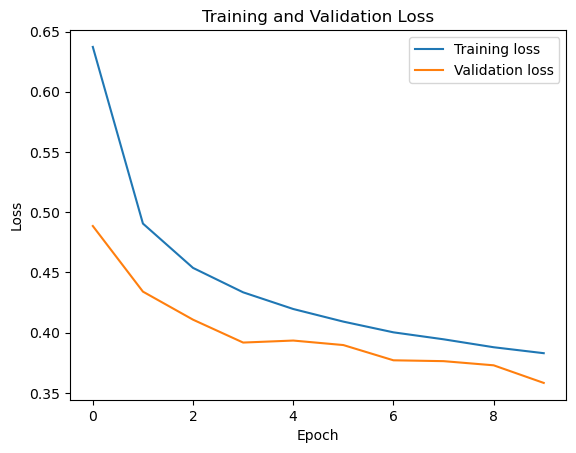

In [25]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

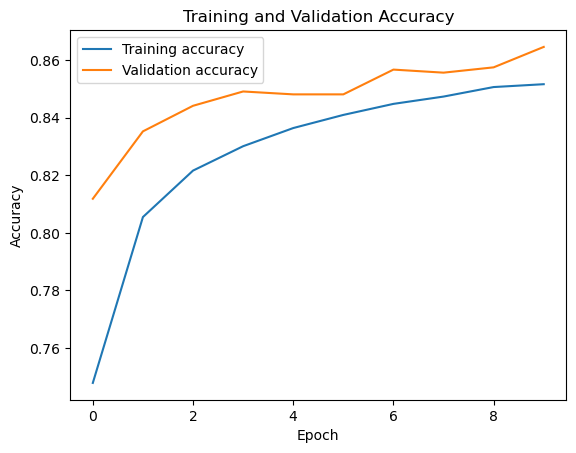

In [26]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()